# Notebook 4: Recurring Issue Detection (Unsupervised Clustering)

The classifier tells us the category. Inside a category there are usually a few **recurring problems**: for example, inside "bug"
some people say a page crashes, others that changes don't save. Finding these themes tells the support team what keeps coming back.

There are no labels for themes, so this is **unsupervised learning**: we group tickets whose descriptions are similar.

**Method**
1. Turn each description into a **text embedding**, a short list of numbers where similar sentences get similar vectors.
   We use TF-IDF followed by TruncatedSVD (also called LSA, latent semantic analysis), which compresses the words into 30 "topic" dimensions.
2. Group the embeddings with **K-Means**.
3. Choose the number of groups with the **silhouette score** (how much closer each point is to its own group than to the next one; higher is better).
4. Describe each group with its top words and example tickets, and check that each group really is one coherent problem.

*Optional:* set `USE_SENTENCE_TRANSFORMERS = True` to use a pre-trained sentence-embedding model (`all-MiniLM-L6-v2`) instead of LSA.
It needs `pip install sentence-transformers` and an internet connection the first time. The results below use LSA.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sys.path.append("..")
from src import config

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

TEXT, TARGET, SEED = config.TEXT, config.TARGET, config.SEED
FIG = config.FIGURES
USE_SENTENCE_TRANSFORMERS = False

tickets = pd.read_csv(config.PROCESSED / "tickets_clean.csv", parse_dates=["created_at"])

# Work on unique descriptions and remember how many tickets each one represents
unique = tickets.groupby([TEXT, TARGET]).size().rename("tickets").reset_index()
print("Tickets:", len(tickets), "| unique descriptions:", len(unique))

Tickets: 20000 | unique descriptions: 96


## 1. Text embeddings

In [2]:
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
tfidf_matrix = tfidf.fit_transform(unique[TEXT])
terms = tfidf.get_feature_names_out()

if USE_SENTENCE_TRANSFORMERS:
    from sentence_transformers import SentenceTransformer
    embeddings = SentenceTransformer("all-MiniLM-L6-v2").encode(unique[TEXT].tolist(), normalize_embeddings=True)
else:
    svd = TruncatedSVD(n_components=30, random_state=SEED)
    embeddings = normalize(svd.fit_transform(tfidf_matrix))     # unit length, so distance ~ cosine similarity
    print(f"LSA keeps {svd.explained_variance_ratio_.sum():.0%} of the TF-IDF information in 30 dimensions")

print("Embedding shape:", embeddings.shape)

# similar sentences should have similar vectors: compare one sentence with its nearest neighbours
sim = embeddings @ embeddings.T
i = unique.index[unique[TEXT].str.contains("very slow")][0]
print("\nSentence:", unique.loc[i, TEXT])
for j in np.argsort(-sim[i])[1:4]:
    print(f"  similarity {sim[i, j]:.2f}:", unique.loc[j, TEXT])

LSA keeps 78% of the TF-IDF information in 30 dimensions
Embedding shape: (96, 30)

Sentence: The analytics dashboard page is very slow and takes a long time to load.
  similarity 0.89: The notifications page is very slow and takes a long time to load.
  similarity 0.89: The billing page is very slow and takes a long time to load.
  similarity 0.85: The data export page is very slow and takes a long time to load.


The nearest neighbours of a "page is very slow" sentence are the same complaint about other products, so the embeddings capture similarity the way we want.

## 2. First attempt: cluster all categories together

In [3]:
scores = {}
for k in range(6, 21, 2):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(embeddings, sample_weight=unique["tickets"])
    scores[k] = silhouette_score(embeddings, km.labels_)
best_k = max(scores, key=scores.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in scores.items()}, "-> best k =", best_k)

global_km = KMeans(n_clusters=best_k, n_init=20, random_state=SEED).fit(embeddings, sample_weight=unique["tickets"])
unique["global_cluster"] = global_km.labels_

# purity: share of tickets in a cluster that come from its most common category
purity = unique.groupby("global_cluster").apply(
    lambda g: g.groupby(TARGET)["tickets"].sum().max() / g["tickets"].sum(), include_groups=False)
print(f"Average cluster purity: {purity.mean():.0%}")
print(f"Clusters mixing more than one category: {(purity < 1).sum()} of {best_k}")

Silhouette by k: {6: 0.123, 8: 0.078, 10: 0.103, 12: 0.136, 14: 0.172, 16: 0.18, 18: 0.251, 20: 0.316} -> best k = 20
Average cluster purity: 92%
Clusters mixing more than one category: 3 of 20


Clustering everything at once works reasonably well (most clusters belong to one category), but it has two problems:

- a few clusters mix categories, because short sentences get grouped by shared surface words ("my account", "page") as much as by the actual problem;
- the silhouette score keeps rising as k grows, so there's no clear "natural" number of groups. Any k we pick would be somewhat arbitrary.

Since we already know each ticket's category, a cleaner approach is to **find themes within each category**. That answers the question
the support team actually asks: "what keeps coming up in bug tickets?"

## 3. Themes within each category

For each category we try k = 2 up to 6 and keep the k with the best silhouette score.
If no k reaches a silhouette of 0.1, the sentences are too different to merge sensibly, so each sentence becomes its own theme.

In [4]:
MIN_SILHOUETTE = 0.10
unique["cluster_id"] = ""
choices = []

for cat in sorted(unique[TARGET].unique()):
    idx = unique.index[unique[TARGET] == cat]
    E, w = embeddings[idx], unique.loc[idx, "tickets"]
    best = (None, -1, None)
    for k in range(2, min(6, len(idx) - 1) + 1):
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(E, sample_weight=w)
        s = silhouette_score(E, km.labels_)
        if s > best[1]:
            best = (k, s, km.labels_)
    if best[1] >= MIN_SILHOUETTE:
        labels, k_used = best[2], best[0]
    else:
        labels, k_used = np.arange(len(idx)), len(idx)          # every sentence is its own theme
    unique.loc[idx, "cluster_id"] = [f"{cat}#{l}" for l in labels]
    choices.append({"category": cat, "unique_sentences": len(idx), "themes": k_used,
                    "best_silhouette": round(best[1], 2) if best[0] else None})

pd.DataFrame(choices)

,category,unique_sentences,themes,best_silhouette
0,account_access,3,3,0.00
1,billing_problem,3,3,0.03
2,bug,21,3,0.54
3,feature_request,21,3,0.49
4,how_to,21,3,0.41
5,other,3,3,0.00
6,performance,15,3,0.50
7,security_concern,9,3,0.23


Categories built from product-specific sentences (bug, feature_request, how_to, performance) split cleanly into 3 themes each, with high silhouette scores.
Categories with only a handful of very different sentences (account_access, billing_problem, other) don't group well (silhouette ≈ 0), so each sentence is its own theme.

## 4. Describe each theme

In [5]:
def top_terms(rows, n=4):
    # average TF-IDF of the theme's sentences, weighted by ticket count
    weights = unique.loc[rows, "tickets"].values[:, None]
    mean = np.asarray(tfidf_matrix[rows].multiply(weights).sum(axis=0)).ravel() / weights.sum()
    best = [j for j in np.argsort(-mean)[:n] if mean[j] > 0]     # skip words not in the theme at all
    return ", ".join(terms[best])

summary = []
for cid, g in unique.groupby("cluster_id"):
    rows = g.index.values
    centre = embeddings[rows].mean(axis=0)
    cohesion = float((embeddings[rows] @ (centre / np.linalg.norm(centre))).mean())
    summary.append({
        "cluster_id": cid,
        "category": g[TARGET].iloc[0],
        "theme": top_terms(rows),
        "tickets": int(g["tickets"].sum()),
        "unique_sentences": len(g),
        "cohesion": round(cohesion, 2),                      # 1 = all sentences say the same thing
        "example": g.sort_values("tickets", ascending=False)[TEXT].iloc[0],
    })
summary = pd.DataFrame(summary).sort_values("tickets", ascending=False).reset_index(drop=True)
summary["share_of_category"] = (summary["tickets"] / summary.groupby("category")["tickets"].transform("sum")).round(2)
summary[["category", "theme", "tickets", "share_of_category", "unique_sentences", "cohesion", "example"]]

,category,theme,tickets,share_of_category,unique_sentences,cohesion,example
0,feature_request,"option, option customize, customize, add option",880,0.35,7,0.89,Can you add an option to customize analytics dashboard?
1,bug,"click, message, message click, error",871,0.35,7,0.92,I am seeing an error message when I click on notifications.
2,account_access,"locked multiple, login attempts, multiple, multiple failed",863,0.34,1,1.00,My account was locked after multiple failed login attempts.
3,how_to,"export data, export, section, data",859,0.34,7,0.81,How can I export my data from the billing section?
4,feature_request,"team needs, options, needs advanced, needs",856,0.34,7,0.91,Our team needs more advanced options for api integration.
5,how_to,"help setting, setting, help, need help",856,0.34,7,0.89,I need help setting up login auth for my team.
6,performance,"time load, time, takes long, takes",851,0.34,7,0.94,The login auth page is very slow and takes a long time to load.
7,other,"workspace, check, check workspace",848,0.34,1,1.00,"Something seems off, can you please check my workspace?"
8,billing_problem,"tier, plan billed, higher, higher tier",841,0.34,1,1.00,I downgraded my plan but I am still being billed for the higher tier.
9,other,"general, general question, question, question account",833,0.33,1,1.00,I have a general question about my account.


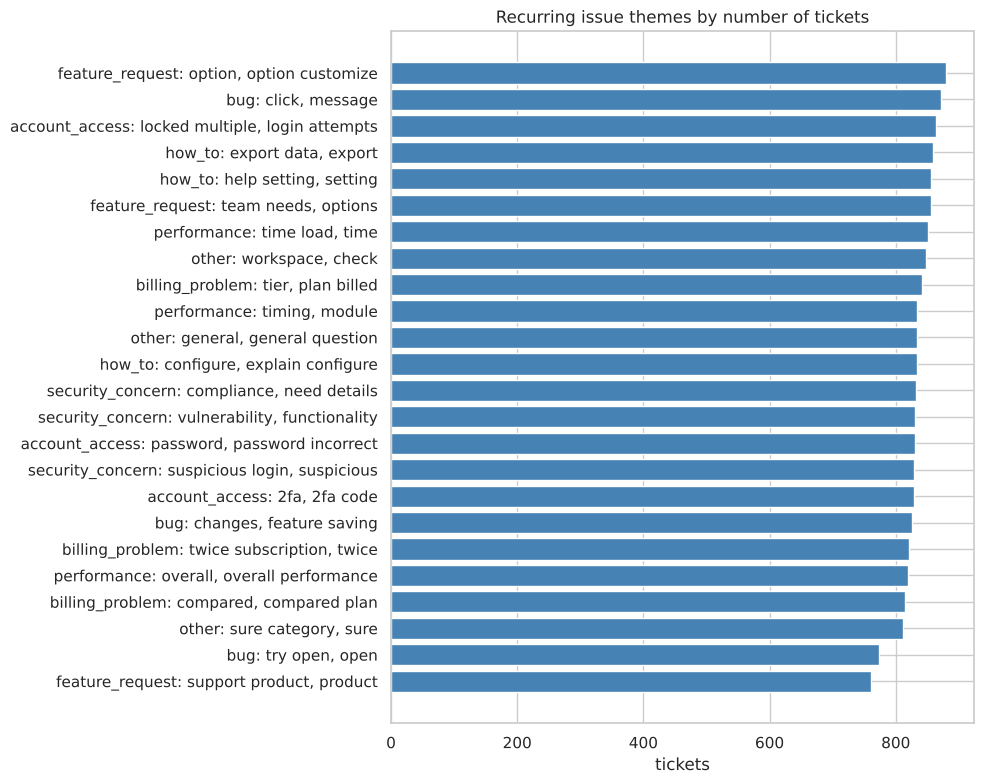

In [6]:
plt.figure(figsize=(10, 8))
order = summary.sort_values("tickets")
labels = order["category"] + ": " + order["theme"].str.split(", ").str[:2].str.join(", ")
plt.barh(labels, order["tickets"], color="steelblue")
plt.title("Recurring issue themes by number of tickets"); plt.xlabel("tickets")
plt.tight_layout(); plt.savefig(FIG / "40_themes.png"); plt.show()

**Is each theme coherent?** The cohesion column is the average cosine similarity between a theme's sentences and the theme centre.
A value near 1 means the sentences all say nearly the same thing. Reading the examples confirms each theme is one recognisable problem:

- **bug**: pages crashing, changes not saving, error messages on click
- **performance**: pages very slow to load, queries timing out, plus the general "performance has degraded" complaint
- **feature_request**: "add an option to customise", "more advanced options", "support for X"
- **how_to**: exporting data, setting things up for a team, configuring properly
- **security_concern**: vulnerabilities in a feature, suspicious logins, encryption and compliance questions

All themes are similar in size (roughly 760 to 880 tickets each), because the synthetic data spreads tickets evenly. In real data the sizes would differ a lot,
and the biggest themes would be the first candidates for a permanent fix or a self-service article.

## 5. Where do the themes sit? A 2-D map

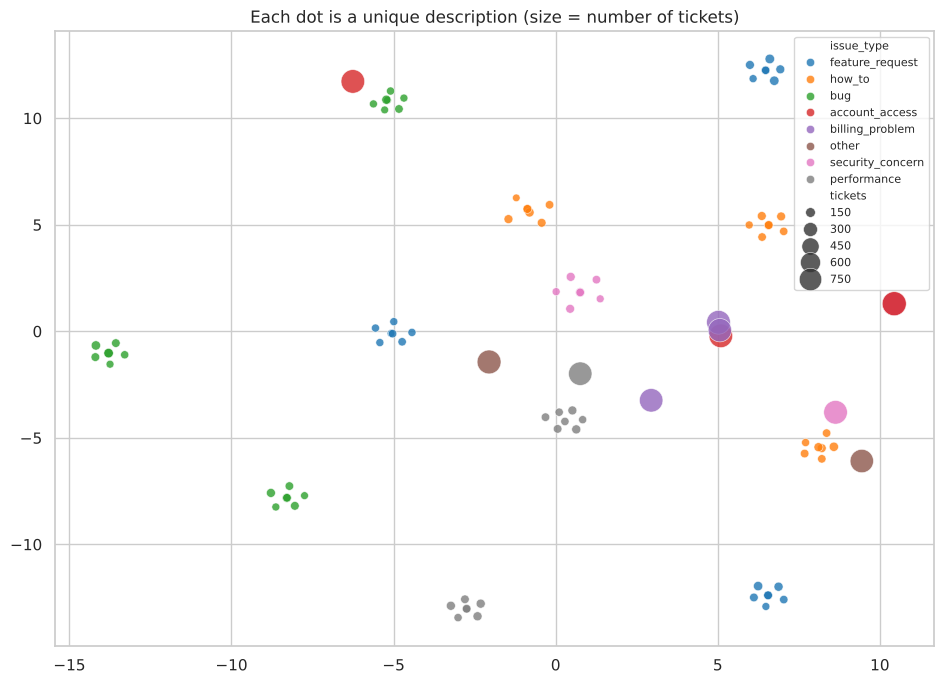

In [7]:
from sklearn.manifold import TSNE
# t-SNE squeezes the 30-dimensional embeddings into 2 dimensions while keeping close sentences close
coords = TSNE(n_components=2, perplexity=10, random_state=SEED, init="pca").fit_transform(embeddings)
plt.figure(figsize=(11, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=unique[TARGET], size=unique["tickets"],
                sizes=(30, 300), alpha=0.8, palette="tab10")
plt.title("Each dot is a unique description (size = number of tickets)")
plt.xlabel(""); plt.ylabel("")
plt.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "41_theme_map.png"); plt.show()

Squeezing 30 dimensions into 2 loses detail, but you can see small tight groups: the 7 product versions of each sentence sit together,
and sentences from the same category are mostly near each other. The single generic sentences sit on their own.

## 6. Are any themes growing?

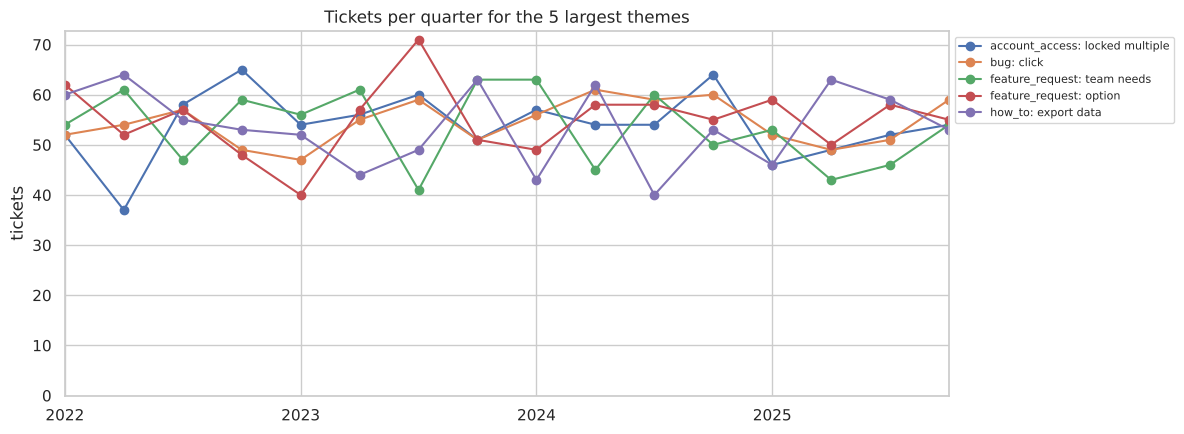

In [8]:
clusters = tickets[["ticket_id", TEXT, "created_at"]].merge(unique[[TEXT, "cluster_id"]], on=TEXT)
clusters = clusters.merge(summary[["cluster_id", "theme", "category"]], on="cluster_id")

top5 = summary["cluster_id"].head(5)
monthly = (clusters[clusters["cluster_id"].isin(top5)]
           .groupby([pd.Grouper(key="created_at", freq="QS"), "cluster_id"]).size().unstack())
names = summary.set_index("cluster_id")
monthly.columns = [f"{names.loc[c, 'category']}: {names.loc[c, 'theme'].split(', ')[0]}" for c in monthly.columns]
monthly.plot(figsize=(12, 4.5), marker="o")
plt.ylim(0, None); plt.title("Tickets per quarter for the 5 largest themes"); plt.xlabel(""); plt.ylabel("tickets")
plt.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "42_theme_trend.png"); plt.show()

No theme is clearly growing or shrinking; they all move around the same level. That matches the flat volume we saw in notebook 01.
In real data, this chart is where a new problem (say, after a software release) would first show up.

## 7. Save for the dashboard

In [9]:
clusters[["ticket_id", "cluster_id", "theme"]].to_csv(config.PROCESSED / "clusters.csv", index=False)
summary.to_csv(config.PROCESSED / "cluster_summary.csv", index=False)
print("Saved clusters.csv:", len(clusters), "tickets | cluster_summary.csv:", len(summary), "themes")
print("Every ticket has a theme:", clusters["ticket_id"].nunique() == len(tickets))

Saved clusters.csv: 20000 tickets | cluster_summary.csv: 24 themes
Every ticket has a theme: True


## Summary

- Descriptions were turned into **text embeddings** (TF-IDF + LSA) and grouped with **K-Means**, choosing k with the silhouette score.
- Clustering all categories together mixed categories, so we cluster **within each category**, which answers "what keeps coming up in this category".
- The result is a set of coherent recurring themes, each with top words, a ticket count, a cohesion score and example descriptions.
- Theme volumes are stable over time in this synthetic data; the trend chart is ready to catch a growing theme in real data.

Saved: `clusters.csv` (theme for every ticket) and `cluster_summary.csv` (one row per theme).